In [30]:
"""
<KNN 모델의 한계를 극복한 모델들>
 * 회귀(Regression) 분석에 사용되는 모델
   - 선형(Linear)인 경우
     -> 선형회귀모델(LinearRegression,
                    선형회귀모델(직선), 다항회귀모델(곡선), 다중회귀모델(포물선) 포함)
        릿지(Ridge), 라쏘(Lasso)

   - 비선형인 경우/분류분석 (앙상블 모델)
     -> 옛날 모델 : 의사결정나무(DecisionTreeRegressor)
     -> 우수 모델 : 랜덤포레스트(RandomForestRegressor),
                   엑스트라트리(ExtraTreesRegressor)


   - 선형/비선형 모두 가능한 모델
     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingRegressor),
                       히스토그램그레디언트부스트(HistGradientBoostingRegressor),
                       엑스지부스트(XGBRegressor),
                       라이트지비엠(LGBMRegressor) - 잘안씀
                   
 * 분류(Classification) 분석(지도학습)에 사용되는 모델
     -> 옛날 모델 : 의사결정나무(DecisionTreeClassifier)
     -> 우수 모델 : 랜덤포레스트(RandomForestClassifier),
                   엑스트라트리(ExtraTreesClassifier)
     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingClassifier),
                       히스토그램그레디언트부스트(HistGradientBoostingClassifier),
                       엑스지부스트(XGBClassifier),
                       라이트지비엠(LGBMClassifier)
                   
 * 분류분석(비지도학습)의 경우(군집분석)에 사용되는 모델
   - 거리 기반 군집 모델 : K-평균(K-Means)
   - 밀도 기반 군집 모델 : DBSCAN

 * 모델링 주로 사용 모델: XGBooting > Ridge > Lasso > RandomForest
"""


'\n<KNN 모델의 한계를 극복한 모델들>\n * 회귀(Regression) 분석에 사용되는 모델\n   - 선형(Linear)인 경우\n     -> 선형회귀모델(LinearRegression,\n                    선형회귀모델(직선), 다항회귀모델(곡선), 다중회귀모델(포물선) 포함)\n        릿지(Ridge), 라쏘(Lasso)\n\n   - 비선형인 경우/분류분석 (앙상블 모델)\n     -> 옛날 모델 : 의사결정나무(DecisionTreeRegressor)\n     -> 우수 모델 : 랜덤포레스트(RandomForestRegressor),\n                   엑스트라트리(ExtraTreesRegressor)\n\n\n   - 선형/비선형 모두 가능한 모델\n     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingRegressor),\n                       히스토그램그레디언트부스트(HistGradientBoostingRegressor),\n                       엑스지부스트(XGBRegressor),\n                       라이트지비엠(LGBMRegressor) - 잘안씀\n                   \n * 분류(Classification) 분석(지도학습)에 사용되는 모델\n     -> 옛날 모델 : 의사결정나무(DecisionTreeClassifier)\n     -> 우수 모델 : 랜덤포레스트(RandomForestClassifier),\n                   엑스트라트리(ExtraTreesClassifier)\n     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingClassifier),\n                       히스토그램그레디언트부스트(HistGradientBoostingClassifier),\n                       엑스지부스트(XGBCl

In [ ]:
%run ../common/libraries.py

# 이번 학습에서 사용하는 주요 라이브러리
# - numpy(np) : 배열 및 수치 데이터 처리
# - matplotlib(plt) : 그래프 시각화
# - train_test_split : 훈련/검증/테스트 데이터 분리
# - KNeighborsRegressor : KNN 회귀 모델
# - mean_absolute_error : MAE 평가
# - mean_squared_error : MSE 평가


In [32]:
### 농어의 길이
perch_length= np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )


### 농어 무게
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )


In [33]:
perch_length.shape, perch_weight.shape

((56,), (56,))

In [34]:
"""
IV (X)= perch_length
DV (y)= perch_weight
"""

'\nIV (X)= perch_length\nDV (y)= perch_weight\n'

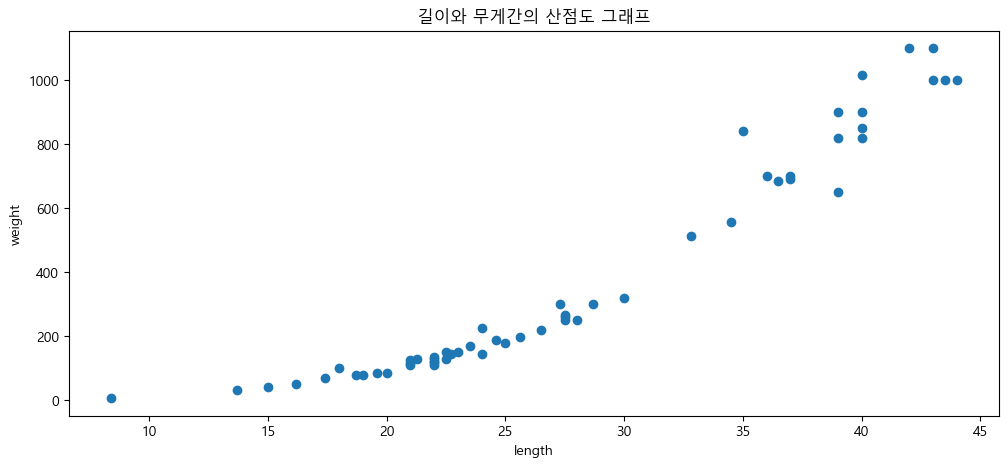

In [35]:
plt.title("길이와 무게간의 산점도 그래프")
plt.scatter(perch_length, perch_weight)

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [36]:
### (해석)
# - x축의 길이가 커질수록, y축의 무게가 커지는 우상향의 양의 상관관계를 나타내고 있음
# - 좌하향은 곡선을 보이고 있으며, x축의 중간이후 직선을 보이고 있음
# - 독립변수 길이를 이용하여, 종속변수 무게를 예측하기 위해서는
#   --> 우상향 선형을 해석할 수 있는 선형모델인 회귀모델을 사용하는 것이 타당함


# - 선형모델 : 회귀모델을 사용
# - 선형에는 직선, 곡선, 포물선이 있음
# - 직선 : 직선의 방정식 사용(y=ax + b)
#        : a는 기울기(가중치라고 칭합니다.), b는 y절편
# - 곡선 : 곡선의 방정식 사용(y=ax^2 + bx + c)
#        : a와 b는 기울기(가중치), c는 y절편
# - 포물선 : 포물선 방정식(y=ax1 + bx2, + cx3 .... N)
#         : a,b,c...는 기울기(가중치), N은 y절편


# - 우리가 알고 있는 값 : 지도학습이므로, 독립변수(x)와 종속변수(y)
# - 모델이 훈련(학습, 공부)하면서 찾아내는 값 : 기울기, y절편 (선형의 패턴 찾아냄)


데이터 분리하기

In [37]:
#테스트 = 0.75 : 훈련 = 0.25

X= perch_length
y= perch_weight
train_input, test_input, train_target, test_target = train_test_split(X, y, test_size= 0.25, random_state=42)

print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)


(42,) (42,)
(14,) (14,)


In [38]:
#IV는 무조건 2차원이어야 함!!

# reshape(행, 렬): numpy function,
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)
train_input.shape
test_input.shape

(14, 1)

Modeling

In [39]:
# KNeighborsRegressor 클래스이므로 생성

"""
<머신러닝 분류 분석>
 - 사용모델 : k-최근접 이웃모델(KNN : K-Nearest Neighbors)
 - 머신러닝에서 가장 간단한 모델
 - 다른 모델들과 비교시에 사용되기도 함(현장에서는 많이 사용 안함)


<KNN 처리 방식>
 - 예측값과 가장 가까운 이웃의 갯수의 비율을 이용하여
 - 가까운 이웃의 비율이 높은(많은) 쪽에 속한 무게들의 평균을 제공해주는 방식



<사용 라이브러리>
 - 사용 패키지 : sklearn.neighbors
 - 사용 모델(클래스) : KNeighborsClassifier
 - 분류모델들은 이름 뒤에 Classifier가 붙어 있음
 - 회귀모델들은 이름 뒤에 Regressor가 붙어 있음
"""


'\n<머신러닝 분류 분석>\n - 사용모델 : k-최근접 이웃모델(KNN : K-Nearest Neighbors)\n - 머신러닝에서 가장 간단한 모델\n - 다른 모델들과 비교시에 사용되기도 함(현장에서는 많이 사용 안함)\n\n\n<KNN 처리 방식>\n - 예측값과 가장 가까운 이웃의 갯수의 비율을 이용하여\n - 가까운 이웃의 비율이 높은(많은) 쪽에 속한 무게들의 평균을 제공해주는 방식\n\n\n\n<사용 라이브러리>\n - 사용 패키지 : sklearn.neighbors\n - 사용 모델(클래스) : KNeighborsClassifier\n - 분류모델들은 이름 뒤에 Classifier가 붙어 있음\n - 회귀모델들은 이름 뒤에 Regressor가 붙어 있음\n'

In [40]:
# 1. 모델 생성
# n_neibors : 보통 홀수
# hyperparamete: 사람 관여해서 값을 수정하는 변수들 > 모델 예측 성능을 조정하는 변수
knr = KNeighborsRegressor()
knr

# 2. 모델 훈련 (모델 패턴찾기)
# 훈련: 회귀에서 기울기와 y절편 찾기
# fit(훈련 IV, 훈련 DV): supervised (문제, 정답)
# **important** fit() 훈련 함수에는 훈련데이터만 사용! 검증/테스트 데이터는 사용하지 않음!!
knr.fit(train_input, train_target)

# 3. 훈련 및 테스트의 독립/종속 변수를 이용하여 정확도(결정 계수) 확인하기
# 결정계수 = Residual (R2) : 훈련에 대한 정확도
# 정확도는 확률(%), residual는 추정치 의미 (오차있음)
# 사용하는 함수: score(IV, DV)
# # <score 함수 : 예측 정확도를 구함>
# 1. 독립변수를 이용해서 예측(훈련(fit)된 결과를 이용해서 예측)
# 2. 예측한 결과(Yn)와 실제 정답(넘어준 종속변수)과 비교하여 결과를 출력
# 3. 결과값 : 0~1 범위의 값(1에 가까울수록 예측을 잘함)
#          : 표현 단어 (예측력이 좋다. 설명력이 좋다. 라고 표현함)
# 결정계수 확인 아래에..
train_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)
print(train_score, test_score)

# Overfitting 판단 근거
# - 가장 이상적인 기준: 훈련 > 검증 > 테스트 (또는 훈련 > 검증 < 테스트) (또는 훈련 = 검증 = 테스트)
# - 가장 이상적인 기준을 완벽하게 찾되 모델이라고 표현
# 과소적합: 훈련 < 검증
# 과대적합: 훈련이 1.0 또는 훈련과 검증의 차이가 보통 0.1 이상인 경우
# 과소/과대 적합일 경우, 진행안함 > 하이퍼파라미터 튜닝으로 다시 돌아가서 조정
# 처리방법

# 4. 테스트 데이터로 예측하기
# use IV  
train_pred = knr.predict(train_input)
print(train_pred)
print(train_target)

test_pred = knr.predict(test_input)
print(test_pred)
print(test_target)

0.9698823289099254 0.992809406101064
[  88.6  123.    79.6   70.6  723.   193.   847.   847.  1010.   123.
   95.   123.   174.   248.  1010.   847.   174.   113.   248.   847.
  659.   224.   723.    60.   140.    60.   719.   694.2  248.   167.
  847.   113.   168.   123.  1010.   136.    79.6  719.   123.   193.
  990.   659. ]
[  85.  135.   78.   70.  700.  180.  850.  820. 1000.  120.   85.  130.
  225.  260. 1100.  900.  145.  115.  265. 1015.  514.  218.  685.   32.
  145.   40.  690.  840.  300.  170.  650.  110.  150.  110. 1000.  150.
   80.  700.  120.  197. 1100.  556.]
[  60.    79.6  248.   122.   136.   847.   311.4  183.4  847.   113.
 1010.    60.   248.   248. ]
[   5.9  100.   250.   130.   130.   820.   320.   188.   900.   125.
 1000.    51.5  250.   300. ]


In [41]:
"""
<회귀모델 오차 확인 방법>
 - 평균절대오차(MAE, Mean Absolute Error)
 - 평균제곱오차(MSE, Mean Squere Error)
 - 보통 평균절대오차(MAE)를 이용하여 모델간의 성능 비교 평가 시 사용됨
 - 비교 평가는 모델 선정의 기준이 된다는 의미임


<오차 확인 순서>
 1. 훈련 모델을 이용하여 예측(Predict)
 2. 예측 결과와 종속변수(정답)를 이용하여 오차 확인(주로 테스트 데이터를 활용)


<사용 라이브러리>
 - 패키지 : sklearn.metrics
 - 사용함수 : mean_absolute_error, mean_squere_error
"""

'\n<회귀모델 오차 확인 방법>\n - 평균절대오차(MAE, Mean Absolute Error)\n - 평균제곱오차(MSE, Mean Squere Error)\n - 보통 평균절대오차(MAE)를 이용하여 모델간의 성능 비교 평가 시 사용됨\n - 비교 평가는 모델 선정의 기준이 된다는 의미임\n\n\n<오차 확인 순서>\n 1. 훈련 모델을 이용하여 예측(Predict)\n 2. 예측 결과와 종속변수(정답)를 이용하여 오차 확인(주로 테스트 데이터를 활용)\n\n\n<사용 라이브러리>\n - 패키지 : sklearn.metrics\n - 사용함수 : mean_absolute_error, mean_squere_error\n'

In [42]:
# 1. 테스트 데이터로 예측하기
# 위의 예측 결과 사용 (test_pred 변수)

# 2. 오차 확인
# mean_absolute_error (정답, 예측값)
mae = mean_absolute_error(test_target, test_pred)
print(mae)

mse = mean_squared_error(test_target, test_pred)
print(mse)

""" 
결과 해석: KNN 회귀모델 이용했을때, X를 이용해 y를 예측하고자할때 약 +-19.157 정도의 오차 발생하는 모델
"""

19.157142857142862
721.7385714285714


' \n결과 해석: KNN 회귀모델 이용했을때, X를 이용해 y를 예측하고자할때 약 +-19.157 정도의 오차 발생하는 모델\n'

성능 향상시키기

In [43]:
"""(회귀 및 분류분석 모두 공통 적용 사항)
<정확도 향상 방법 1 - 과적합 여부 판단하기>
 - 훈련정확도와 검증(또는 테스트)정확도 비교
 - 훈련정확도 < 검증(또는 테스트) 정확도 ==> 과소적합
 - 훈련정확도 > 검증(또는 테스트) 정확도
   --> 값의 차이가 0.1 (0.5) 이상인 경우 ==> 과대 적합이 보인다고 표현함
 - 훈련정확도가 1인 경우 ==> 과대적합
 
<과적합에 따른 모델 판단 여부>
 - 과소적합 : 모델 사용 못함
 - 과대적합 : 훈련정확도가 1인 경우 -> 모델 사용 못함
 - 과대적합 : 0.1 이상 차이인 경우 -> 모델 향상(하이퍼파라메터 튜닝)을 위한 노력 필요
 - 일반화   : 0.1 이내 차이인 경우 -> 모델 사용 가능(하이퍼파라메터 튜닝이 가능하면 수행)
 ** 위에서 0.1 범위는 통상적인 범위이며, 기준은 아님
 
<해결방법>
 - 데이터 양을 늘리기(마지막 해결방법)
 - 특성이 여러개인 경우 데이터 스케일링 (정규화/표준화) 하기
 - 하이퍼파라메터 튜닝하기
 - 다른 모델 사용하기
"""

'(회귀 및 분류분석 모두 공통 적용 사항)\n<정확도 향상 방법 1 - 과적합 여부 판단하기>\n - 훈련정확도와 검증(또는 테스트)정확도 비교\n - 훈련정확도 < 검증(또는 테스트) 정확도 ==> 과소적합\n - 훈련정확도 > 검증(또는 테스트) 정확도\n   --> 값의 차이가 0.1 (0.5) 이상인 경우 ==> 과대 적합이 보인다고 표현함\n - 훈련정확도가 1인 경우 ==> 과대적합\n \n<과적합에 따른 모델 판단 여부>\n - 과소적합 : 모델 사용 못함\n - 과대적합 : 훈련정확도가 1인 경우 -> 모델 사용 못함\n - 과대적합 : 0.1 이상 차이인 경우 -> 모델 향상(하이퍼파라메터 튜닝)을 위한 노력 필요\n - 일반화   : 0.1 이내 차이인 경우 -> 모델 사용 가능(하이퍼파라메터 튜닝이 가능하면 수행)\n ** 위에서 0.1 범위는 통상적인 범위이며, 기준은 아님\n \n<해결방법>\n - 데이터 양을 늘리기(마지막 해결방법)\n - 특성이 여러개인 경우 데이터 스케일링 (정규화/표준화) 하기\n - 하이퍼파라메터 튜닝하기\n - 다른 모델 사용하기\n'

과적합 여부 확인하기

In [44]:
train_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)

print(train_score, test_score, train_score-test_score)

### (과적합 여부 해석)
# - 훈련정확도가 테스트정확도보다 낮기 때문에
# - 예측 모델로 사용하기에는 부적합한 모델임
# - 즉, 과소저합이 발생한 모델임
# - 더 이상 예측 과정은 불필요함


### (과소적합 해결을 위한 방법)
# - 데이터 추가 수집 : x
# - 데이터 스케일링: 정규화/표준화 : o (IV가 하나일때는 할 필요 없음)
# - 하이퍼파라메터 튜닝 : o (즉시 가능)
# - 다른 모델 사용 : x (할수는 있음)


0.9698823289099254 0.992809406101064 -0.022927077191138623


하이퍼파라미터 튜닝하기

In [45]:
### 각 모델별로 성능에 영향을 미치는 변수들이 있음
# - 이런 변수들을 하이퍼파라메터라고 칭함
# - KNN 모델에서는 이웃의갯수(n_neighbors)가 해당됨
# - 하이퍼파라메터 : 사람에 의해 성능에 영향을 미치는 값을 수정하는 대상 변수
# - 모델(클래스) 생성시 또는 생성 후에 하이퍼파라메터 변수의 값을 정의할 수 있음

### KNN 하이퍼파라메터 변수 : 이웃의 갯수
# 훈련정확도가 1이 아니면서, 가장 높은 정확도 시점의 이웃의 갯수 찾아내주세요..
# - 찾은 다음 훈련 및 테스트 정확도 확인하여 비교해 주세요..
### 테스트할 이웃의 갯수 범위 지정
# - 전체 데이터의 갯수 = 49건
# - 최소=3 , 최대=49, 가급적 홀수 갯수만 테스트 (3, 5, 7, 9)

In [46]:
# 클래스 생성
knr = KNeighborsRegressor(n_neighbors=3)
knr

# 훈련시키기
knr.fit(train_input, train_target)

# 훈련 및 테스트 정확도 (결정계수) 계산
train_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)

# 과적합 여부 해석
print(train_score, test_score, train_score-test_score)
# 훈련 > 테스트 이라서 과소적합이 일어나지 않았고, 결정계수들의 차이가 작아 과대적합도 일어나지 않음

0.9804899950518966 0.9746459963987609 0.005843998653135674


In [47]:
# practice 

max_score= 0
max_test_score = 0
max_n = 0

for n in range(3, len(train_input)+1, 2):
    print(n)
    knr = KNeighborsRegressor(n_neighbors= n)
    knr.fit(train_input, train_target)
    train_score = knr.score(train_input, train_target)
    test_score = knr.score(test_input, test_target)
    gap = abs(train_score-test_score)
    print(train_score, test_score, gap)
    
    if train_score < 1 :  # if train_score < 1 and train_score > max_score:
        if train_score > max_score:
            max_score = train_score
            max_test_score = test_score
            max_n = n

print("--------------[1이 아니면서 가장 큰 정확도]--------------")
print (max_score,max_test_score, max_score - max_test_score, max_n, f"가장 높은 훈련 정확도는 이웃갯수가 {max_n}개일 때 입니다")

""" 
결과해석: 훈련정확도가 가장 높은 시점의 이웃의 갯수는 3이며, 일반화는 잘 되었음.
가장 일반화가 잘된 시점의 이웃의 개수는 9로 분석되었음 (선호도 차이: 학자입장이라면 9, 회사입장이라면 3)

단, 훈련정확도는 일반화가 잘된 9일때보다 3일때가 가장 높았음
"""

3
0.9804899950518966 0.9746459963987609 0.005843998653135674
5
0.9698823289099254 0.992809406101064 0.022927077191138623
7
0.9761170732051527 0.9781383949643516 0.002021321759198891
9
0.9693310367551284 0.9692647749722698 6.626178285862316e-05
11
0.9515761381539326 0.970279643030474 0.018703504876541377
13
0.9413423450130075 0.9639044643206888 0.02256211930768126
15
0.930201118360776 0.9554827691127018 0.025281650751925788
17
0.9087778943199959 0.9314058693169347 0.022627974996938804
19
0.8782082893573573 0.900993697623706 0.022785408266348672
21
0.8410922229110086 0.8596922255009882 0.018600002589979625
23
0.7915879473391005 0.8146418957364303 0.02305394839732977
25
0.7452999142836829 0.7667897994036779 0.021489885119994945
27
0.6908904295441316 0.7131817408006262 0.02229131125649464
29
0.6245508306350807 0.6429925427310261 0.018441712095945473
31
0.5505387544219442 0.5653184638150339 0.014779709393089702
33
0.4752451966763833 0.4834613125728193 0.008216115896436005
35
0.3947807136120

' \n결과해석: 훈련정확도가 가장 높은 시점의 이웃의 갯수는 3이며, 일반화는 잘 되었음.\n가장 일반화가 잘된 시점의 이웃의 개수는 9로 분석되었음 (선호도 차이: 학자입장이라면 9, 회사입장이라면 3)\n\n단, 훈련정확도는 일반화가 잘된 9일때보다 3일때가 가장 높았음\n'

In [48]:
#결정된 이웃의 갯수로 모델 훈련시키기

knr = KNeighborsRegressor(n_neighbors= max_n)
knr

# 훈련시키기
knr.fit(train_input, train_target)

# 훈련 및 테스트 정확도 (결정계수) 계산
train_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)

# 과적합 여부 해석
print(train_score, test_score, train_score-test_score)

0.9804899950518966 0.9746459963987609 0.005843998653135674


오차 확인하기(MAE, MSE)

In [49]:
#오차 확인을 위해서는 예측이 선행되어야함
test_pred = knr.predict(test_input)
print(test_pred)

mae = mean_absolute_error(test_target, test_pred)
mse = mean_squared_error(test_target, test_pred)
print(mae, mse)

""" 
해석: KNN모델의 n값에 대한 하이퍼파라미터 튜닝 후 3의 값을 이용하여 훈련된 모델은 무게 예측시에 +-35.42 정도의 오차가 발생하는 모델이다.
"""

[  47.33333333   76.          247.66666667  120.          143.33333333
  921.66666667  275.          183.33333333  773.33333333  120.
 1033.33333333   62.66666667  275.          247.66666667]
35.42380952380951 2544.847142857142


' \n해석: KNN모델의 n값에 대한 하이퍼파라미터 튜닝 후 3의 값을 이용하여 훈련된 모델은 무게 예측시에 +-35.42 정도의 오차가 발생하는 모델이다.\n'

In [50]:
#임의값 1개로 예측

pred_50 = knr.predict([[50]])
print(f"{pred_50[0]:.3f}")


# 훈련 fit함수
# 정확도 score함수
# 예측 predict함수

1033.333


KNN이 예측에 사용한 이웃 확인하기

In [51]:
# distances: 임의값 50 예측하는데 사용된 이웃과의 거리
distances, indexes = knr.kneighbors([[50]])
print(distances, indexes)
#[행번호  독립변수값]

[[6. 7. 7.]] [[34  8 14]]


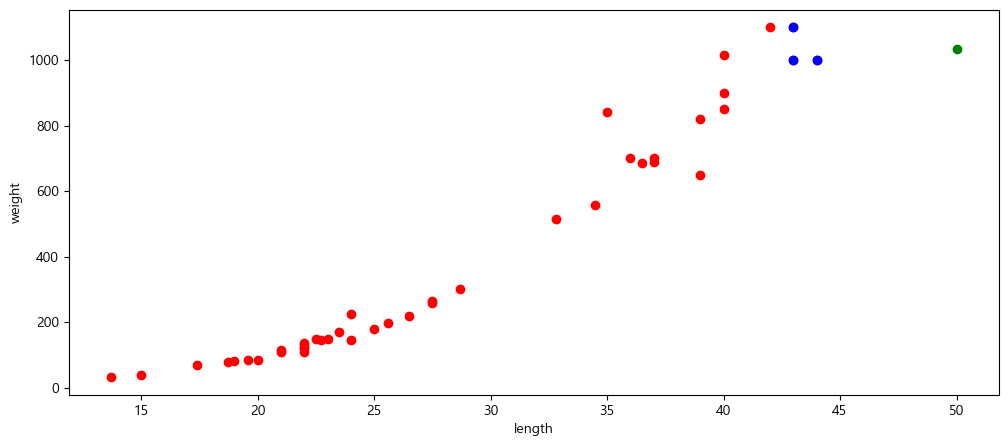

In [52]:
#훈련데이터 산점도
plt.scatter(train_input, train_target, c="red", label="train")
#이웃3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")
#임의값에 대한 산점도
plt.scatter(50, pred_50[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[1033.33333333]


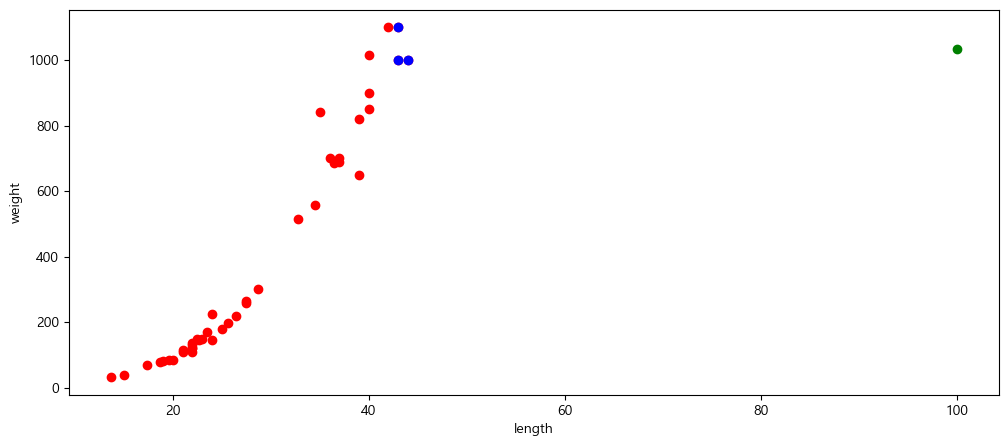

In [53]:
pred = knr.predict([[100]])
print(pred)

distances, indexes = knr.kneighbors([[100]])

plt.scatter(train_input, train_target, c="red", label="train")
#이웃3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")
#임의값에 대한 산점도
plt.scatter(100, pred[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[1033.33333333]


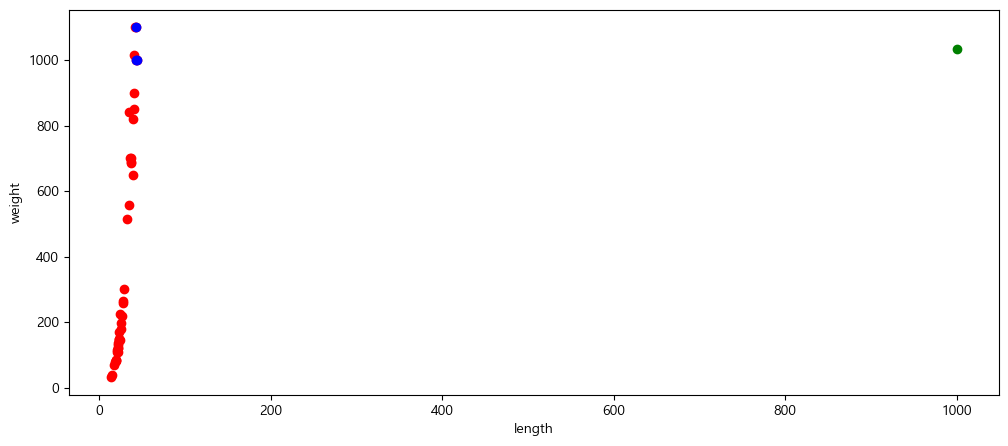

In [54]:
pred = knr.predict([[1000]])
print(pred)

distances, indexes = knr.kneighbors([[1000]])

plt.scatter(train_input, train_target, c="red", label="train")
#이웃3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")
#임의값에 대한 산점도
plt.scatter(1000, pred[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[47.33333333]


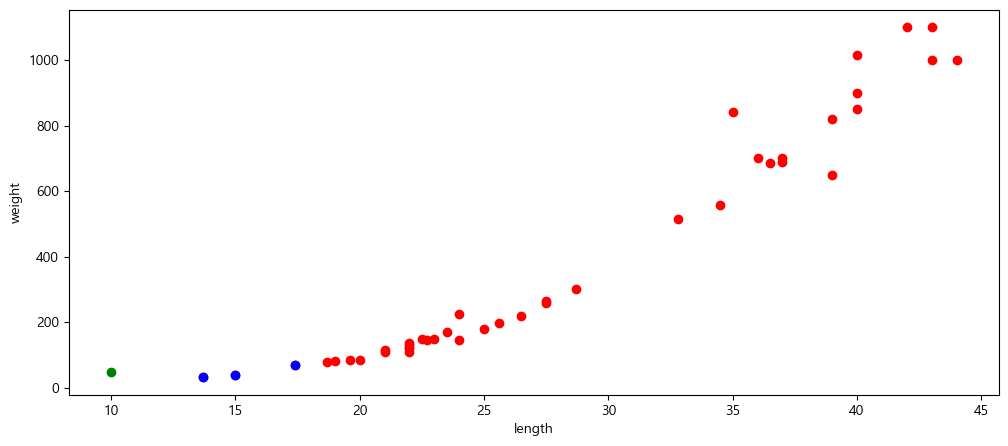

In [55]:
pred = knr.predict([[10]])
print(pred)

distances, indexes = knr.kneighbors([[10]])

plt.scatter(train_input, train_target, c="red", label="train")
#이웃3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")
#임의값에 대한 산점도
plt.scatter(10, pred[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[47.33333333]


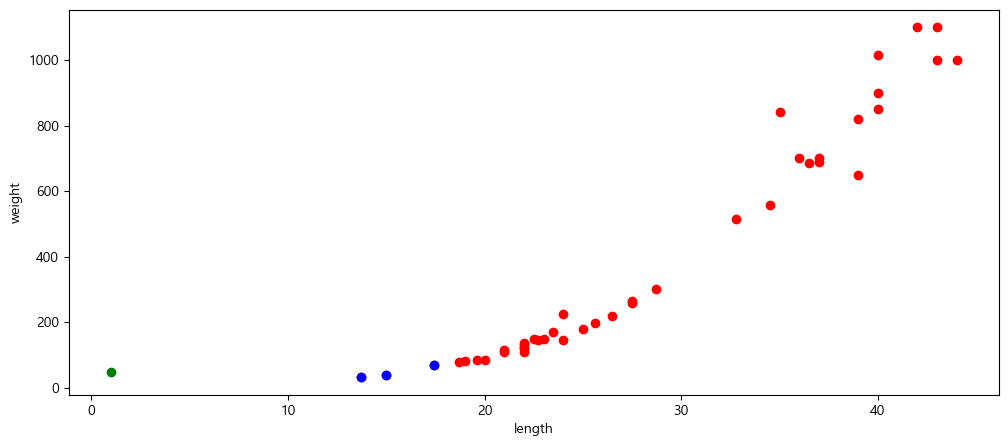

In [56]:
pred = knr.predict([[1]])
print(pred)

distances, indexes = knr.kneighbors([[1]])

plt.scatter(train_input, train_target, c="red", label="train")
#이웃3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")
#임의값에 대한 산점도
plt.scatter(1, pred[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[  47.33333333 1033.33333333]


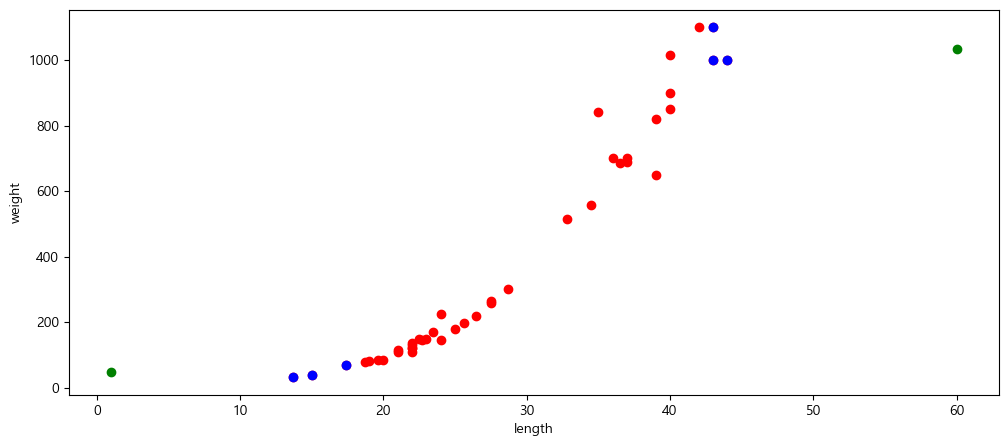

In [57]:
pred = knr.predict([[1],[60]])
print(pred)

distances, indexes = knr.kneighbors([[1], [60]])

plt.scatter(train_input, train_target, c="red", label="train")
#이웃3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")
#임의값에 대한 산점도
plt.scatter([1, 60], pred, c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [58]:
""" 
KNN 오류와 한계: IV의 최소치와 최대치를 넘어서는 순간 오류 발생. 값은 나오나 정확도가 떨어짐

 - 예측에 사용된 독립변수의 길이 값이 훈련데이터의 독립변수 최대길이값(max)보다 큰 경우에는
  --> 항상 같은 무게를 예측하는 오류가 발생하며, 사용되는 이웃의 갯수도 동일함
 - 가장가까운 이웃을 이용하는 모델의 특성 한계 때문에 발생함
 - 훈련데이터의 독립변수 x(길이)의 최대 길이값보다 큰 값들에 대해서는 예측결과가 불확실함

 ==> 따라서, 다른 모델을 사용해야함

"""

' \nKNN 오류와 한계: IV의 최소치와 최대치를 넘어서는 순간 오류 발생. 값은 나오나 정확도가 떨어짐\n\n - 예측에 사용된 독립변수의 길이 값이 훈련데이터의 독립변수 최대길이값(max)보다 큰 경우에는\n  --> 항상 같은 무게를 예측하는 오류가 발생하며, 사용되는 이웃의 갯수도 동일함\n - 가장가까운 이웃을 이용하는 모델의 특성 한계 때문에 발생함\n - 훈련데이터의 독립변수 x(길이)의 최대 길이값보다 큰 값들에 대해서는 예측결과가 불확실함\n\n ==> 따라서, 다른 모델을 사용해야함\n\n'

"""
<KNN 모델의 한계를 극복한 모델들>
 * 회귀(Regression) 분석에 사용되는 모델
   - 선형(Linear)인 경우
     -> 선형회귀모델(LinearRegression,
                    선형회귀모델(직선), 다항회귀모델(곡선), 다중회귀모델(포물선) 포함)
        릿지(Ridge), 라쏘(Lasso)

   - 비선형인 경우/분류분석 (앙상블 모델)
     -> 옛날 모델 : 의사결정나무(DecisionTreeRegressor)
     -> 우수 모델 : 랜덤포레스트(RandomForestRegressor),
                   엑스트라트리(ExtraTreesRegressor)


   - 선형/비선형 모두 가능한 모델
     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingRegressor),
                       히스토그램그레디언트부스트(HistGradientBoostingRegressor),
                       엑스지부스트(XGBRegressor),
                       라이트지비엠(LGBMRegressor) - 잘안씀
                   
 * 분류(Classification) 분석(지도학습)에 사용되는 모델
     -> 옛날 모델 : 의사결정나무(DecisionTreeClassifier)
     -> 우수 모델 : 랜덤포레스트(RandomForestClassifier),
                   엑스트라트리(ExtraTreesClassifier)
     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingClassifier),
                       히스토그램그레디언트부스트(HistGradientBoostingClassifier),
                       엑스지부스트(XGBClassifier),
                       라이트지비엠(LGBMClassifier)
                   
 * 분류분석(비지도학습)의 경우(군집분석)에 사용되는 모델
   - 거리 기반 군집 모델 : K-평균(K-Means)
   - 밀도 기반 군집 모델 : DBSCAN

 * 모델링 주로 사용 모델: XGBooting > Ridge > Lasso > RandomForest
"""